<a href="https://colab.research.google.com/github/ridanoor0110/DSC_110/blob/main/Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/nhanes_final.csv")
df.head()


,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN


Transforming Variables

In [16]:
#To see the amount of unique values available in "education" we do the following
df['education'].unique()

#create dictionary called edu_map
education_map = {
    1: 'Less than 9th grade',
    2: '9-11th grade',
    3: 'high school grad',
    4: 'some college degree',
    5: 'college grad',
    9: 'do not know',
}

#apply the mapping
df['education_label'] = df['education'].map(education_map).fillna('Missing')

In [17]:
#display counts of each label/mapping category
df['education_label'].value_counts()

,count
education_label,
Missing,4139
college grad,2625
some college degree,2370
high school grad,1749
9-11th grade,666
Less than 9th grade,373
do not know,11


In [20]:
#repeat for has_diabetes field
df['has_diabetes'].unique()

diabetes_map = {
    1: 'has Diabetes',
    2: 'no Diabetes',
    3: 'borderline',
    9: 'do not know',
}

df['diabetes_label'] = df['has_diabetes'].map(diabetes_map).fillna('Missing')

df['diabetes_label'].value_counts()

,count
diabetes_label,
no Diabetes,10371
has Diabetes,1081
borderline,284
Missing,193
do not know,4


Data Summarization: One numerical value

In [29]:
#numberical data thats normally distributed, use mean and standard deviation for central tendency and for non-normal distribution use median.
#numerical variables in our data
df['age'].mean()

#we can make values more presentable by rounding and printing with text
age_mean = round(df['age'].mean(),2)

print(f"the average age of NHANES respondents is {age_mean}")


the average age of NHANES respondents is 38.32


In [30]:
#calculating standard deviation
df['age'].std()

25.60199011389104

In [31]:
#calculating median
df['age'].median()


37.0

In [42]:
#calculating quartiles (1st and third) (when data is not normally distributed)
df['age'].quantile([0.25])
df['age'].quantile([0.75])

#to display summary statistics, use describe
df['age'].describe()

df['age'].describe().apply(lambda x: format(x, 'f'))
#formats to display without scientific notation



,age
count,11933.000000
mean,38.317858
std,25.601990
min,0.000000
25%,13.000000
50%,37.000000
75%,62.000000
max,80.000000


In [39]:
#VIEW THE MOST REPEATED VALUE
df['age'].mode()

,age
0,80.0


Data Visualization for One Numerical Value

<Axes: >

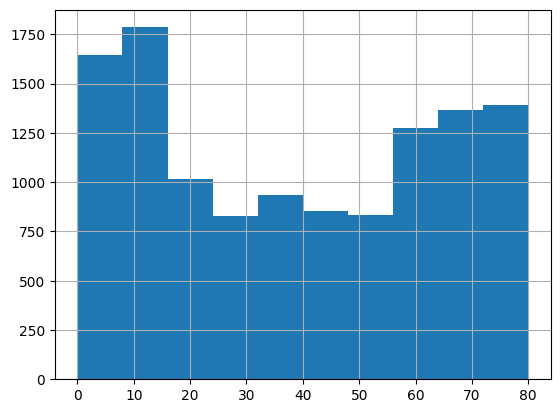

In [43]:
df['age'].hist()
#creates histogram for age

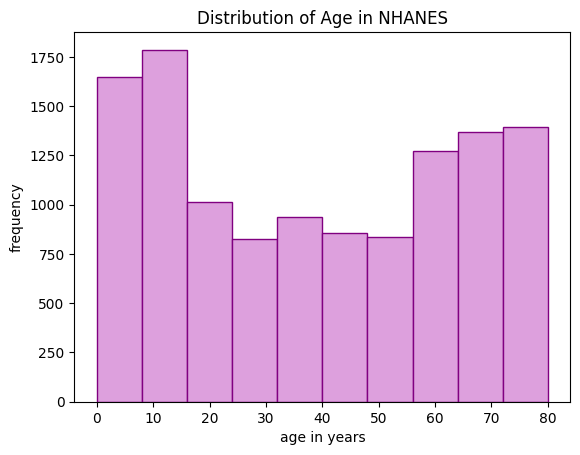

In [62]:
#visualizing with axes labels and titles
#in the hist() bracket, we can use edgecolor to customize the borders of each histogram bar and color to custotmize the bar color
df['age'].hist(edgecolor = 'purple', color = 'plum')
plt.title("Distribution of Age in NHANES")
plt.ylabel("frequency")
plt.xlabel("age in years")

plt.grid(False)
#removes grid lines for aesthetics purposes


summarization/vizualization of one categorical data


In [64]:
df['education_label'].value_counts(normalize=True) * 100
#display education categories as percentages for better visualization.

,proportion
education_label,
Missing,34.685326
college grad,21.997821
some college degree,19.860890
high school grad,14.656834
9-11th grade,5.581161
Less than 9th grade,3.125786
do not know,0.092181


Text(0.5, 0, 'category of education')

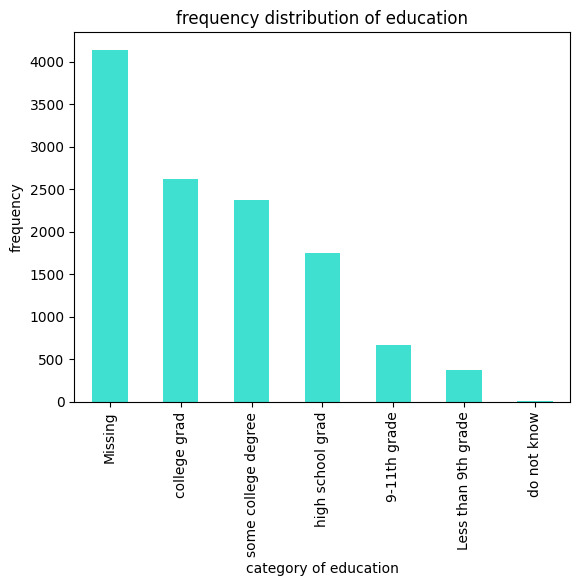

In [68]:
#plots bar chart for education_label
df['education_label'].value_counts().plot(kind='bar', color ='turquoise')
plt.title("frequency distribution of education")
plt.ylabel("frequency")
plt.xlabel("category of education")

Two numerical variables

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

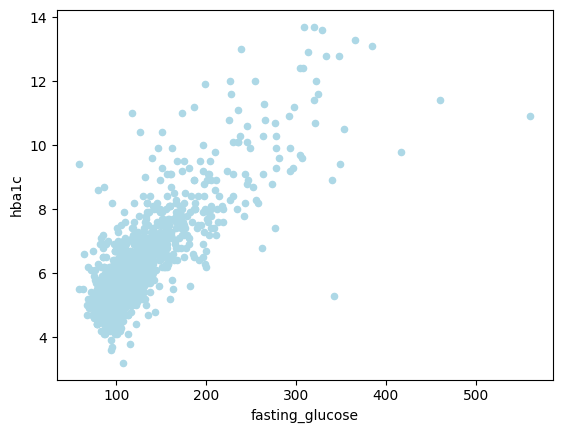

In [71]:
#visualizing two numerical variables with a scatterplot
df.plot(x='fasting_glucose', y='hba1c', kind='scatter', color='lightblue')

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

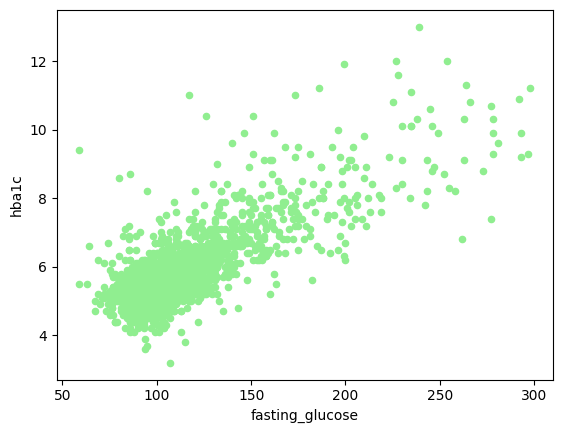

In [80]:
df_no_outliers = df[df['fasting_glucose']<300]
df_no_outliers.plot(x='fasting_glucose', y='hba1c', kind='scatter', color='lightgreen')
#filters out outliers above 300 (fasting_glucose) so that we can create a scatter plot with more spread and better distribution.


Two categorical variables

<Axes: xlabel='bmi_category'>

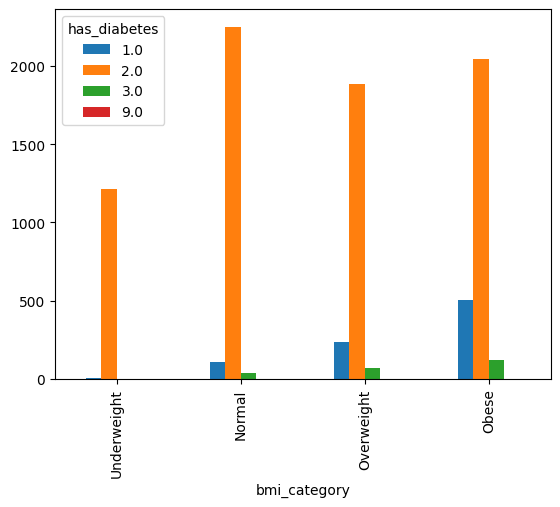

In [88]:
#vizualizing two categorical variables, by first categorizing our bmi data

df['has_diabetes'].unique()

diabetes_map = {
    1: 'has Diabetes',
    2: 'no Diabetes',
    3: 'borderline',
    9: 'do not know',
}
df['bmi_category'] = pd.cut(df['bmi'],
                            bins = [0, 18.5, 25, 30, 100],
                            labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
)
pd.crosstab(df['bmi_category'], df['diabetes_label'], normalize='index') * 100

#normalize='index' percentage calculated per row instead of nromalize=True which calculates percentage across all data

#plot bargraph for data
pd.crosstab(df['bmi_category'], df['has_diabetes']).plot(kind='bar')

One numerical and one categorical

In [90]:
df.groupby('diabetes_label')['bmi'].mean()
#this code calculates the average BMI for each diabetes group in the dataframe

,bmi
diabetes_label,
Missing,NaN
borderline,32.068559
do not know,19.250000
has Diabetes,32.981412
no Diabetes,26.439797


<Axes: title={'center': 'bmi'}, xlabel='diabetes_label'>

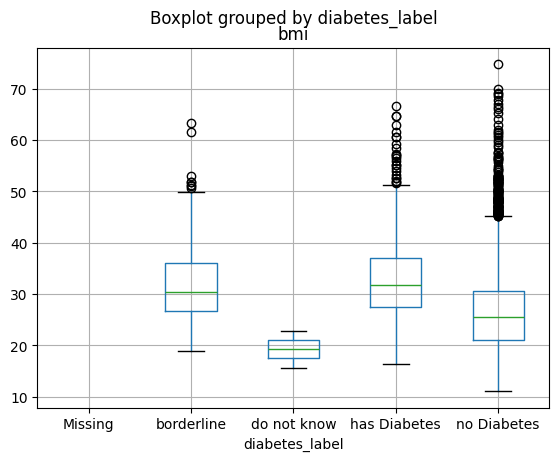

In [93]:
df.boxplot(column='bmi', by='diabetes_label')
#plots boxplot for bmi against diabetes categories